# Telco Customer Churn - Exploratory Data Analysis (EDA)

**Objective:** Find out why customers leave (churn) a telecom company and which customer groups are at the highest risk.

**Dataset:** WA_Fn-UseC_-Telco-Customer-Churn.csv (7043 customers, 21 columns)

*Only the methods covered in class (NumPy, Pandas, Matplotlib, Seaborn) are used.*

**Steps:**
1. Load and understand the data
2. Data cleaning
3. Outlier detection (IQR method)
4. Univariate analysis
5. Bivariate analysis
6. Multivariate analysis
7. Business questions
8. Insights and conclusion

## 1. Load and Understand the Data

In [255]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [256]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [257]:
# first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [258]:
# last 5 rows
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [259]:
# number of rows and columns
df.shape

(7043, 21)

In [260]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [261]:
# data types and non-null count
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [262]:
# statistical summary of all columns
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


**Column meaning (short):**
- `tenure` - number of months the customer has stayed
- `MonthlyCharges` - amount charged every month
- `TotalCharges` - total amount charged so far
- `Contract` - Month-to-month / One year / Two year
- `Churn` - did the customer leave? (Yes / No) --> **target column**

## 2. Data Cleaning

In [263]:
# duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# duplicate customer ids
print("Duplicate customerID:", df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customerID: 0


In [264]:
# null values
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


No null values are shown, but `TotalCharges` is stored as text (str) instead of a number.
It probably has blank spaces. Let's find them and convert the column to float.

In [265]:
# check for blank values (empty space) in TotalCharges
(df['TotalCharges'] == ' ').sum()

np.int64(11)

In [266]:
# check the rows having blank TotalCharges
df[df['TotalCharges'] == ' '][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All 11 rows with blank TotalCharges have tenure = 0.
These customers have not accumulated any tenure-based charges yet.

For this analysis, I will treat their TotalCharges as 0 and convert the column to float.

In [267]:
# replace blank with 0 and change the data type to float
df['TotalCharges'] = df['TotalCharges'].replace(' ', '0')
df['TotalCharges'] = df['TotalCharges'].astype(float)
df['TotalCharges'].dtype

dtype('float64')

In [268]:
# SeniorCitizen is 0/1 --> change to No/Yes like the other columns
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Yes'})
df['SeniorCitizen'].value_counts()

,count
SeniorCitizen,
No,5901
Yes,1142


`No internet service` and `No phone service` are **kept as separate groups**. These customers do not have the service at all, which is different from customers who have the service but chose `No`. Merging them would hide real differences (for example, customers with no internet churn only 7.4%).

In [269]:
# check the groups in OnlineSecurity and MultipleLines
print(df['OnlineSecurity'].value_counts())
print()
print(df['MultipleLines'].value_counts())

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


In [270]:
# Create numeric churn column (Yes = 1, No = 0)
df['Churn_flag'] = df['Churn'].map({'Yes': 1, 'No': 0}).astype(int)

df[['Churn', 'Churn_flag']].head()

,Churn,Churn_flag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [271]:
# customerID is only an identifier --> not useful for analysis
df = df.drop('customerID', axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   object 
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


## 3. Outlier Detection (IQR Method)

In [272]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for column in num_cols:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_limit) | (df[column] > upper_limit)]

    print(f"{column}: Lower = {lower_limit:.2f}, Upper = {upper_limit:.2f}, Outliers = {len(outliers)}")

tenure: Lower = -60.00, Upper = 124.00, Outliers = 0
MonthlyCharges: Lower = -46.02, Upper = 171.38, Outliers = 0
TotalCharges: Lower = -4683.52, Upper = 8868.67, Outliers = 0


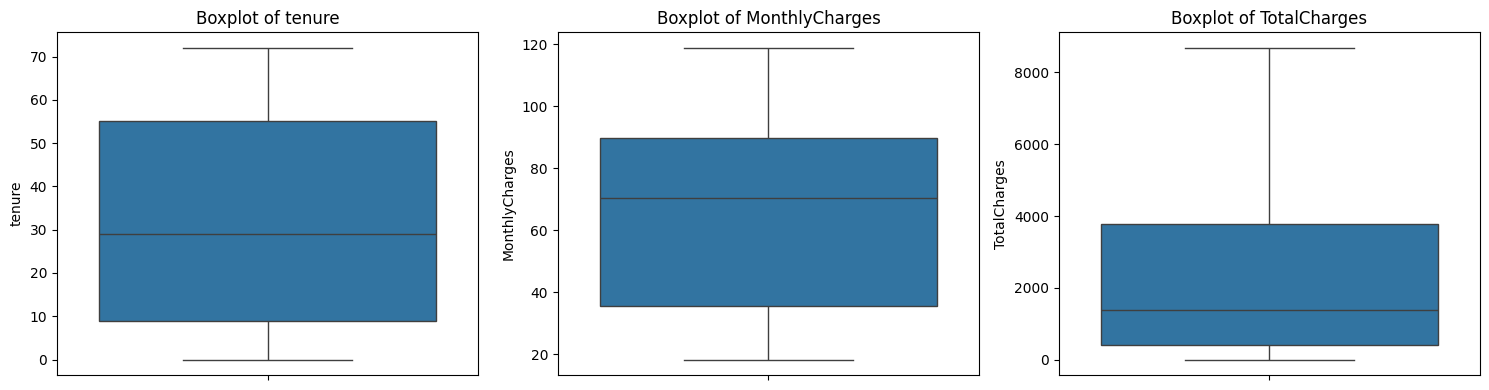

In [273]:
plt.figure(figsize=(15, 4))

for i, column in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(data=df, y=column)
    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

**Result:** No potential outliers were detected in `tenure`, `MonthlyCharges`, or `TotalCharges` using the 1.5 x IQR rule. Therefore, no outlier treatment was applied.

## 4. Univariate Analysis

### 4.1 Target column - Churn

In [274]:
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts() / len(df) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


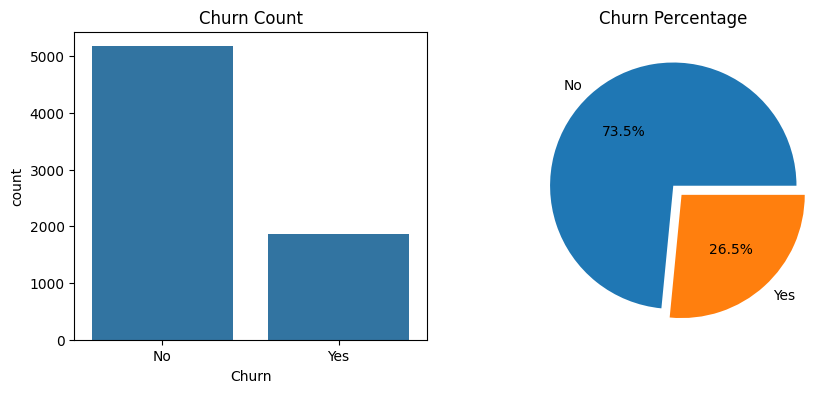

In [275]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Churn')
plt.title("Churn Count")

plt.subplot(1, 2, 2)
plt.pie(df['Churn'].value_counts(), labels=['No', 'Yes'], autopct="%1.1f%%", explode=[0, 0.1])
plt.title("Churn Percentage")

plt.show()

About **26.5%** of customers have churned. The data is imbalanced (more customers stayed than left).

### 4.2 Numerical columns

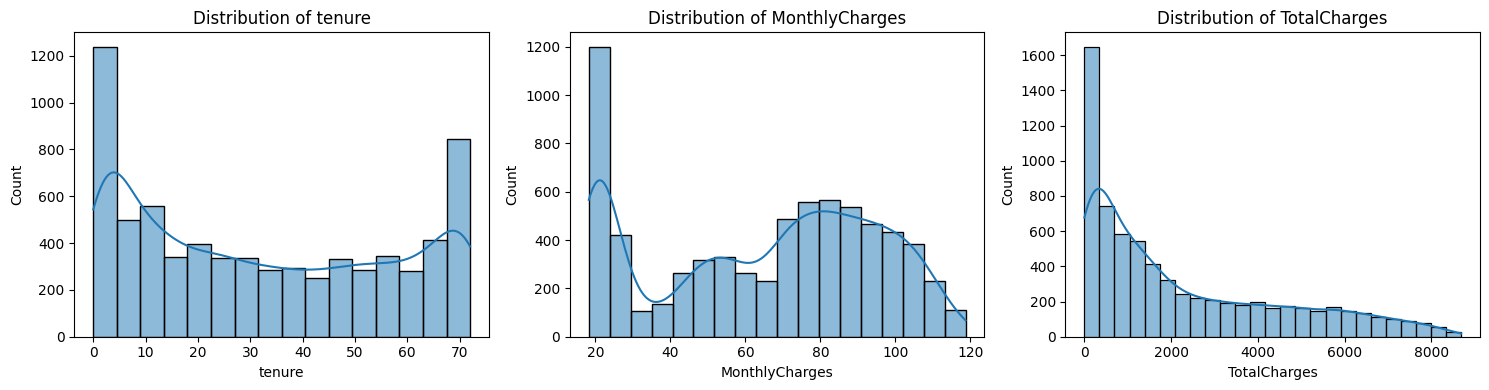

In [276]:
plt.figure(figsize=(15, 4))

for i, column in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    sns.histplot(data=df, x=column, kde=True)
    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

In [277]:
df[num_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


- `tenure` has two peaks - many brand new customers (0-5 months) and many long-term customers (70+ months).
- `MonthlyCharges` has a big group at the low end (about 20 - basic phone-only plans) and the rest spread between 60 and 110.
- `TotalCharges` is right skewed because most customers have a low tenure.

### 4.3 Categorical columns

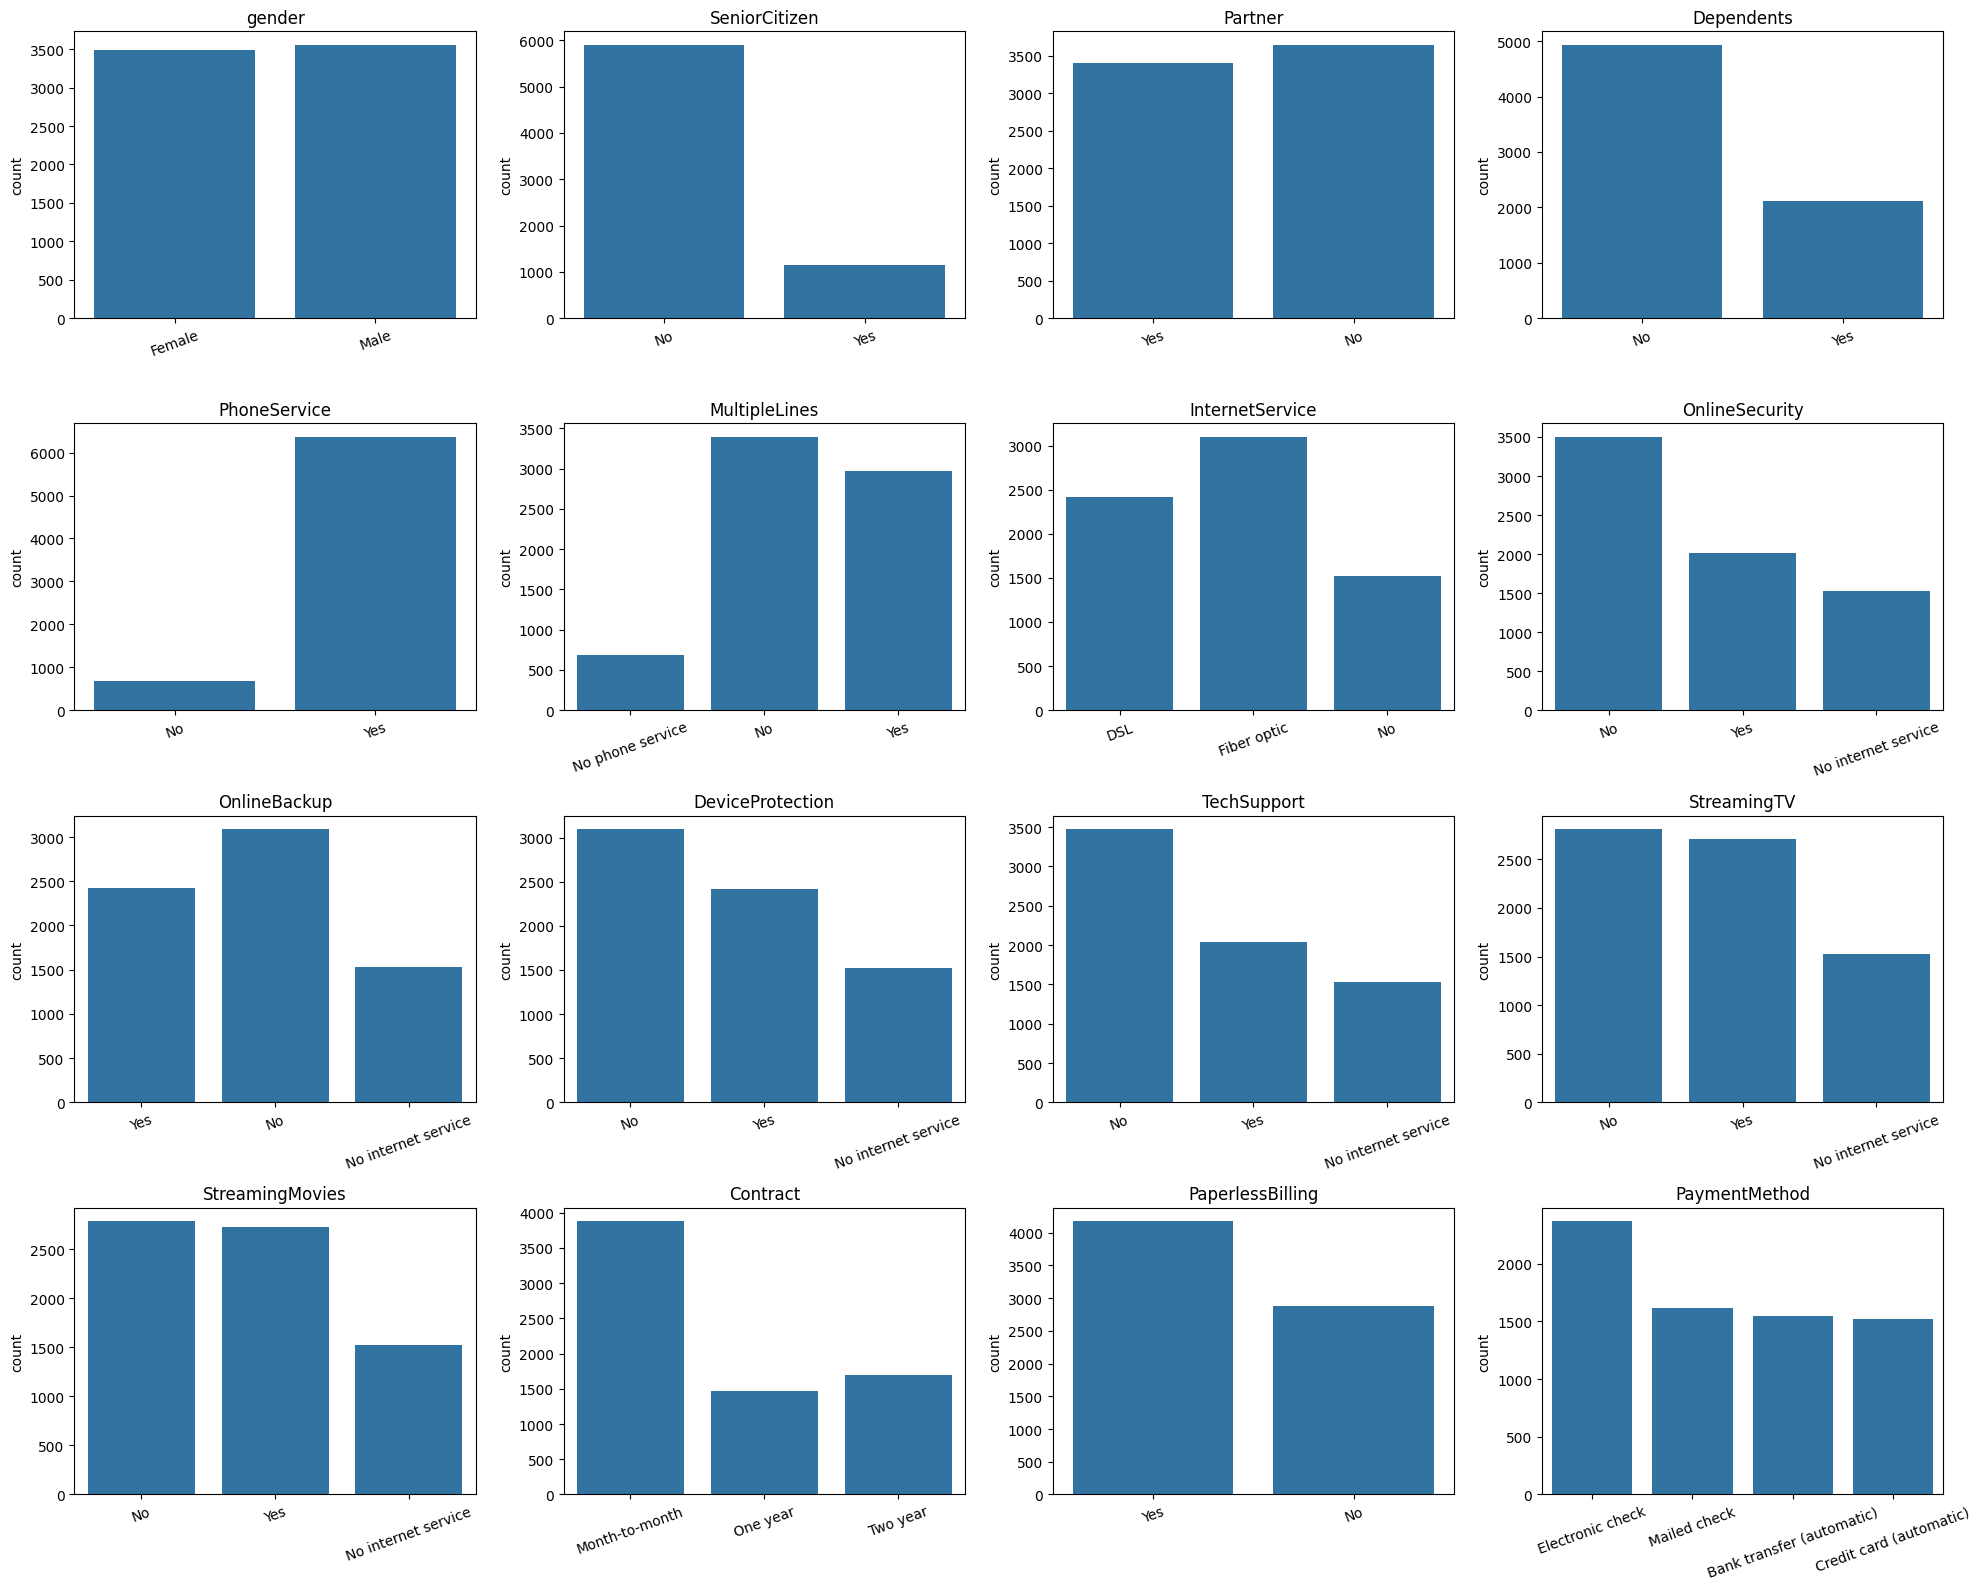

In [278]:
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
            'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
            'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
            'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

plt.figure(figsize=(20, 16))

for i, column in enumerate(cat_cols):
    plt.subplot(4, 4, i + 1)
    sns.countplot(data=df, x=column)
    plt.title(column)
    plt.xlabel("")
    plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [279]:
# most common contract type and internet service
print(df['Contract'].value_counts())
print()
print(df['InternetService'].value_counts())

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


- More than half of the customers (3875) are on a **Month-to-month** contract.
- **Fiber optic** is the most used internet service (3096 customers).
- Gender is almost equally split between the two groups.

## 5. Bivariate Analysis (Features vs Churn)

### 5.1 Categorical columns vs Churn

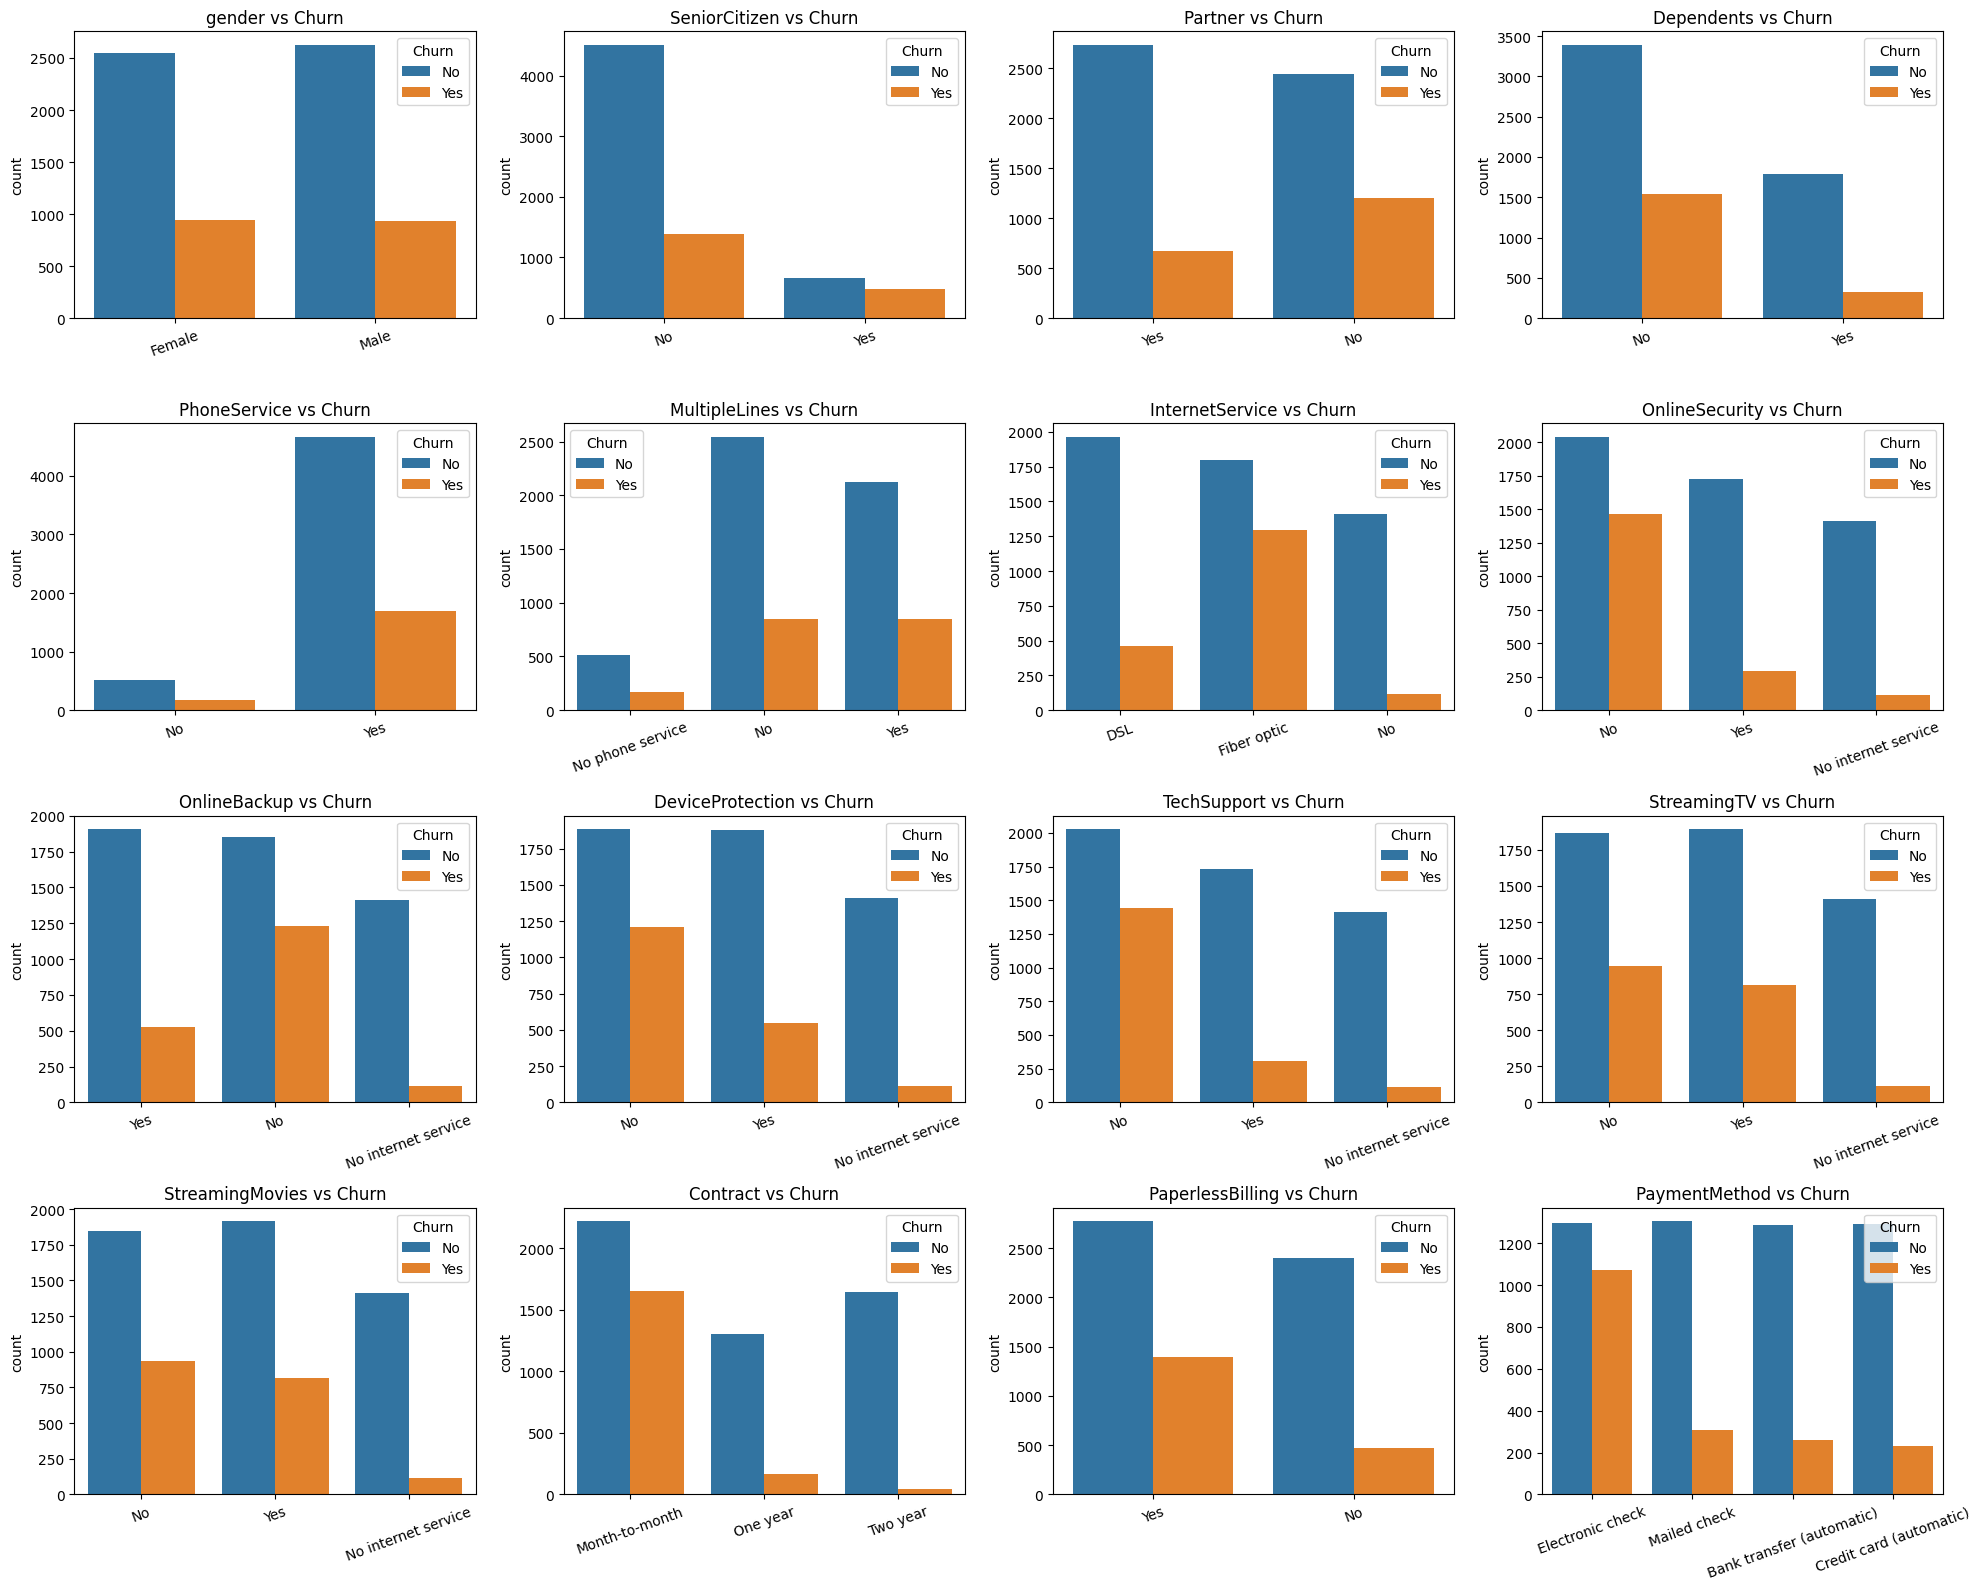

In [280]:
plt.figure(figsize=(20, 16))

for i, column in enumerate(cat_cols):
    plt.subplot(4, 4, i + 1)
    sns.countplot(data=df, x=column, hue='Churn')
    plt.title(f"{column} vs Churn")
    plt.xlabel("")
    plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

Counts can be misleading because groups have different sizes.
The **churn rate (%)** inside each group is a better comparison. The mean of `Churn_flag` x 100 gives the churn rate.

In [281]:
# churn rate (%) for every categorical column
for column in cat_cols:
    print(column)
    print((df.groupby(column)['Churn_flag'].mean() * 100).round(1))
    print()

gender
gender
Female    26.9
Male      26.2
Name: Churn_flag, dtype: float64

SeniorCitizen
SeniorCitizen
No     23.6
Yes    41.7
Name: Churn_flag, dtype: float64

Partner
Partner
No     33.0
Yes    19.7
Name: Churn_flag, dtype: float64

Dependents
Dependents
No     31.3
Yes    15.5
Name: Churn_flag, dtype: float64

PhoneService
PhoneService
No     24.9
Yes    26.7
Name: Churn_flag, dtype: float64

MultipleLines
MultipleLines
No                  25.0
No phone service    24.9
Yes                 28.6
Name: Churn_flag, dtype: float64

InternetService
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn_flag, dtype: float64

OnlineSecurity
OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: Churn_flag, dtype: float64

OnlineBackup
OnlineBackup
No                     39.9
No internet service     7.4
Yes                    21.5
Name: Churn_flag, dtype: float64

DeviceProtection
DeviceProtection
No       

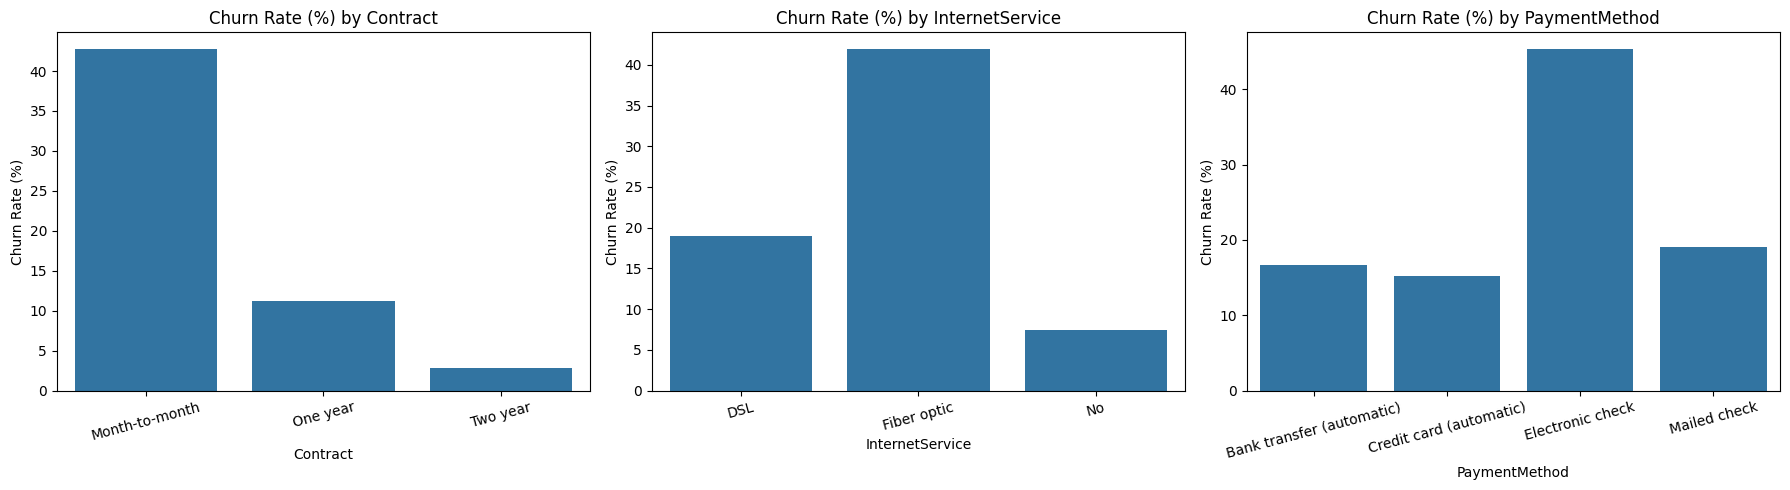

In [282]:
# churn rate by Contract, InternetService and PaymentMethod
plt.figure(figsize=(18, 5))

for i, column in enumerate(['Contract', 'InternetService', 'PaymentMethod']):
    plt.subplot(1, 3, i + 1)
    rate = (df.groupby(column)['Churn_flag'].mean() * 100).reset_index()
    sns.barplot(data=rate, x=column, y='Churn_flag')
    plt.title(f"Churn Rate (%) by {column}")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

- **Contract:** Month-to-month customers churn at about 42.7%, one year at 11.3% and two year at only 2.8%.
- **Internet service:** Fiber optic customers churn the most (41.9%) compared to DSL (19.0%) and no internet (7.4%).
- **Payment method:** Electronic check users churn at 45.3%, while automatic payments (bank transfer / credit card) are only around 15 - 17%.

### 5.2 Numerical columns vs Churn

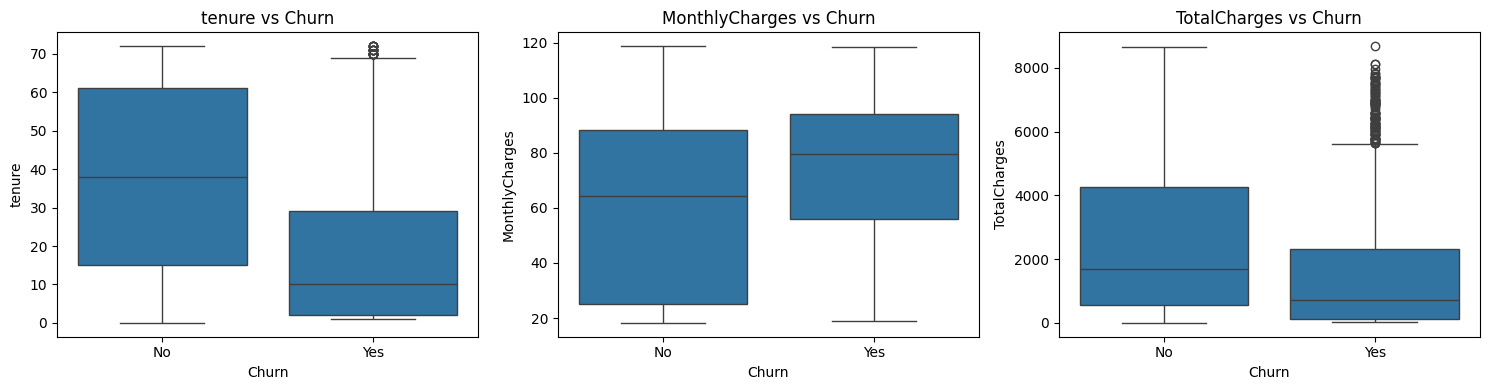

In [283]:
plt.figure(figsize=(15, 4))

for i, column in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(data=df, x='Churn', y=column)
    plt.title(f"{column} vs Churn")

plt.tight_layout()
plt.show()

In [284]:
df.groupby('Churn')[num_cols].agg(['mean', 'median']).round(1)

tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
No      37.6   38.0           61.3   64.4       2549.9  1679.5
Yes     18.0   10.0           74.4   79.6       1531.8   703.6

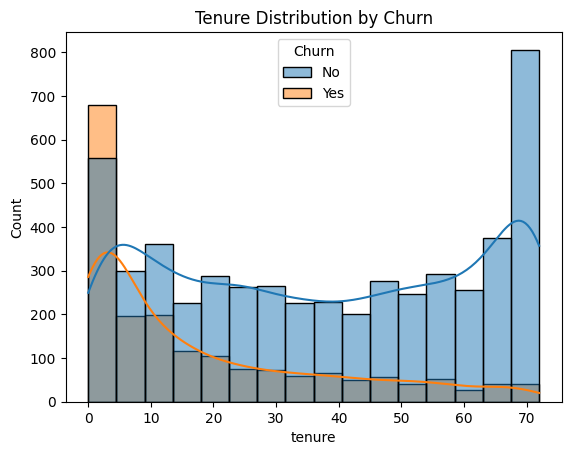

In [285]:
sns.histplot(data=df, x='tenure', hue='Churn', kde=True)
plt.title("Tenure Distribution by Churn")
plt.show()

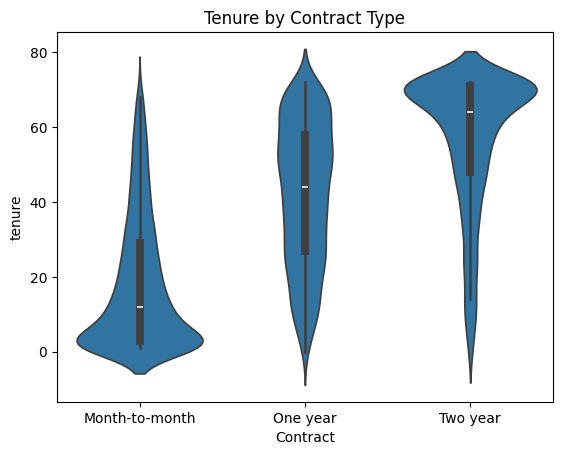

In [286]:
# violin plot - tenure by contract type
sns.violinplot(data=df, x='Contract', y='tenure')
plt.title("Tenure by Contract Type")
plt.show()

- Churned customers have a much **lower tenure** (median 10 months) than customers who stayed (median 38 months).
- Churned customers pay **more per month** (median 79.6 vs 64.4).
- Churn is highest in the early months - customers who survive the first year are far more likely to stay.

### 5.3 Tenure groups

  tenure_group  churn_rate
0         0-12   47.438243
1        13-24   28.710938
2        25-48   20.388959
3        49-72    9.513176


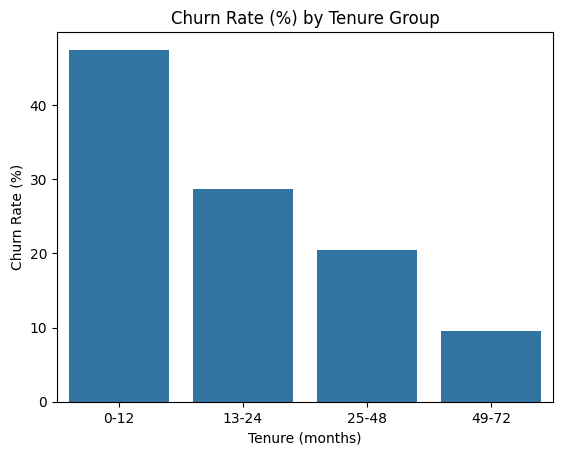

In [287]:
# churn rate (%) for each tenure band using conditional filtering
rate_0_12 = df[df['tenure'] <= 12]['Churn_flag'].mean() * 100
rate_13_24 = df[(df['tenure'] > 12) & (df['tenure'] <= 24)]['Churn_flag'].mean() * 100
rate_25_48 = df[(df['tenure'] > 24) & (df['tenure'] <= 48)]['Churn_flag'].mean() * 100
rate_49_72 = df[df['tenure'] > 48]['Churn_flag'].mean() * 100

tenure_churn = pd.DataFrame({'tenure_group': ['0-12', '13-24', '25-48', '49-72'],
                             'churn_rate': [rate_0_12, rate_13_24, rate_25_48, rate_49_72]})
print(tenure_churn)

sns.barplot(data=tenure_churn, x='tenure_group', y='churn_rate')
plt.title("Churn Rate (%) by Tenure Group")
plt.xlabel("Tenure (months)")
plt.ylabel("Churn Rate (%)")
plt.show()

Churn falls steadily with tenure: **47.4%** in the first year to just **9.5%** after 4 years.

## 6. Multivariate Analysis

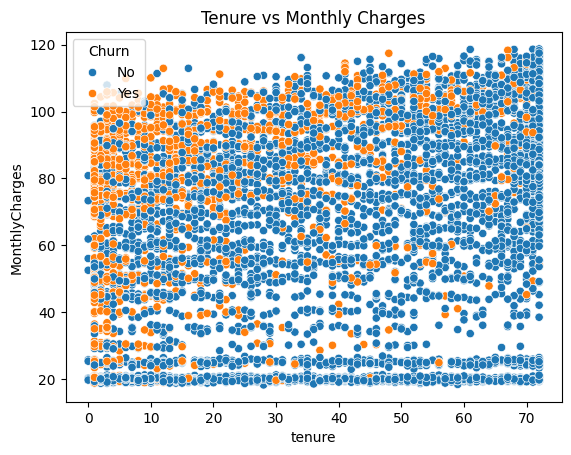

In [288]:
# monthly charges vs tenure, colored by churn
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn')
plt.title("Tenure vs Monthly Charges")
plt.show()

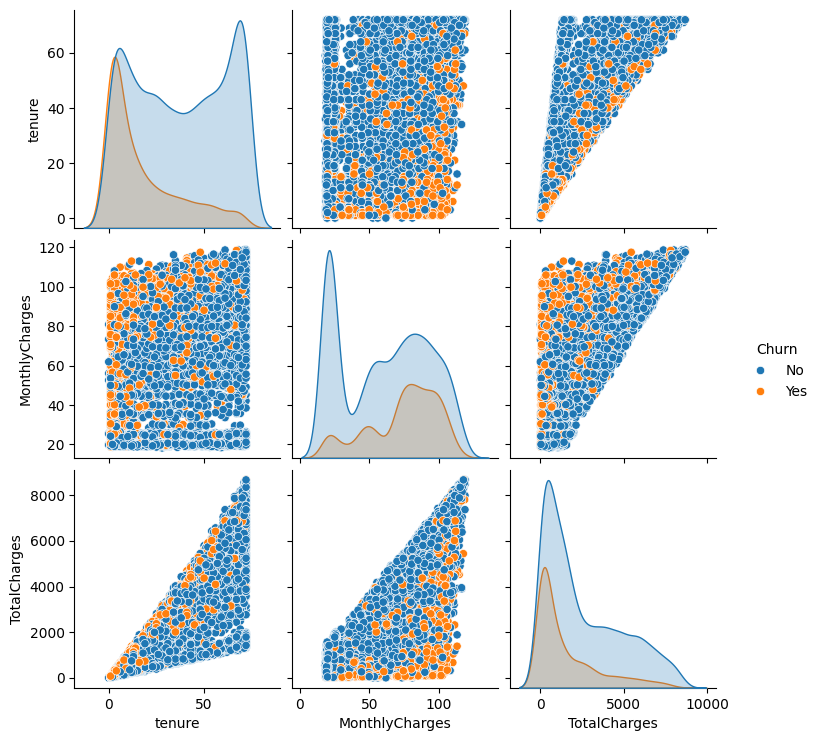

In [289]:
sns.pairplot(data=df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']], hue='Churn')
plt.show()

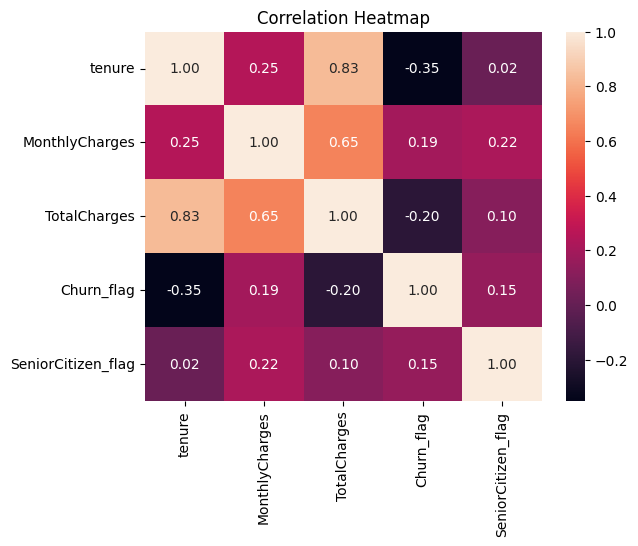

In [290]:
# SeniorCitizen is text (No/Yes) --> create a numeric column so it is included in the correlation
df['SeniorCitizen_flag'] = df['SeniorCitizen'].replace({'Yes': '1', 'No': '0'}).astype(int)

# correlation heatmap
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

- `TotalCharges` has a strong positive correlation with `tenure` (0.83). Customers who stay longer generally accumulate more charges.
- `tenure` has a negative correlation with churn (-0.35), indicating that longer-tenure customers are less likely to churn in this dataset.
- `MonthlyCharges` has a small positive correlation with churn (0.19), indicating an association between higher monthly charges and churn.
- `SeniorCitizen` (converted to 0/1 for this plot) has a small positive correlation with churn (0.15), meaning senior citizens churn somewhat more often.

**Note:** Correlation shows association, not causation.

In [291]:
# churn rate (%) by Contract and InternetService together
(df.groupby(['Contract', 'InternetService'])['Churn_flag'].mean() * 100).round(1)

Contract        InternetService
Month-to-month  DSL                32.2
                Fiber optic        54.6
                No                 18.9
One year        DSL                 9.3
                Fiber optic        19.3
                No                  2.5
Two year        DSL                 1.9
                Fiber optic         7.2
                No                  0.8
Name: Churn_flag, dtype: float64

The riskiest group is **Month-to-month + Fiber optic** customers, with a churn rate of about 54.6%.

## 7. Business Questions

In [292]:
# 1. How many customers churned?
print("Churned customers:", df['Churn_flag'].sum())
print("Overall churn rate: %.1f%%" % (df['Churn_flag'].mean() * 100))

Churned customers: 1869
Overall churn rate: 26.5%


In [293]:
# 2. How much monthly charges are associated with churned customers?
churned_charges = df[df['Churn'] == 'Yes']['MonthlyCharges'].sum()
total_charges = df['MonthlyCharges'].sum()

print("Monthly charges associated with churned customers:", round(churned_charges, 2))
print("Percentage of total monthly charges: %.1f%%" % (churned_charges / total_charges * 100))

Monthly charges associated with churned customers: 139130.85
Percentage of total monthly charges: 30.5%


In [294]:
# 3. Which contract type has the highest churn rate?
(df.groupby('Contract')['Churn_flag'].mean() * 100).sort_values(ascending=False)

,Churn_flag
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


In [295]:
# 4. Do customers with tech support / online security churn less?
for column in ['TechSupport', 'OnlineSecurity']:
    print((df.groupby(column)['Churn_flag'].mean() * 100).round(1))
    print()

TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: Churn_flag, dtype: float64

OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: Churn_flag, dtype: float64



In [296]:
# 5. Do senior citizens churn more?
(df.groupby('SeniorCitizen')['Churn_flag'].mean() * 100).round(1)

,Churn_flag
SeniorCitizen,
No,23.6
Yes,41.7


In [297]:
# 6. Do customers with a partner or dependents churn less?
for column in ['Partner', 'Dependents']:
    print((df.groupby(column)['Churn_flag'].mean() * 100).round(1))
    print()

Partner
No     33.0
Yes    19.7
Name: Churn_flag, dtype: float64

Dependents
No     31.3
Yes    15.5
Name: Churn_flag, dtype: float64



In [298]:
# 7. Average monthly charges - churned vs not churned
df.groupby('Churn')['MonthlyCharges'].mean().round(2)

,MonthlyCharges
Churn,
No,61.27
Yes,74.44


In [299]:
# 8. Average monthly charges by internet service
df.groupby('InternetService')['MonthlyCharges'].mean().round(1)

,MonthlyCharges
InternetService,
DSL,58.1
Fiber optic,91.5
No,21.1


## 8. Key Insights and Conclusion

**Overall:** 1869 of 7043 customers (**26.5%**) churned. The monthly charges associated with these customers are about **139K of the 456K total monthly charges (30.5%)**, which is higher than their share of customers because churned customers pay more per month on average.

**Main findings**
1. **Contract type shows the largest differences in churn rates among the categories analysed.** Month-to-month churn is 42.7%, versus 11.3% (one year) and 2.8% (two year).
2. **New customers are most at risk.** 47.4% of customers in their first 12 months churn, falling to 9.5% after 4 years.
3. **Fiber optic customers churn the most (41.9%)**, even though they pay the highest bills (average 91.5 per month vs 58.1 for DSL). This may point to a price or service-quality issue.
4. **Electronic check users churn at 45.3%**, versus about 15 - 17% for automatic payment methods.
5. **Customers who subscribe to Tech Support and Online Security have lower churn rates than customers who do not subscribe to these services.** Among customers with internet, churn is about 15% for those who subscribe, compared to about 42% for those who do not (nearly three times higher).
6. **Seniors, customers without partners/dependents and customers with paperless billing churn more.**
7. **Gender and phone service show relatively small differences in churn rates** (gender 26.9% vs 26.2%, phone service 24.9% vs 26.7%).

**Recommendations**
- Offer discounts or benefits to move month-to-month customers to 1 or 2 year contracts.
- Give new customers extra attention during the first 12 months (onboarding calls, welcome offers).
- Review fiber optic pricing and service quality.
- Encourage automatic payment methods with small incentives.
- Promote Tech Support and Online Security bundles, and test whether they reduce churn.